# Task 1 – N-Queens: Logic mệnh đề (SAT/Glucose3) và Local Search (Min-Conflicts)

Notebook này (Người A) gồm: mô hình hoá bài toán, mã hoá CNF, giải bằng **Glucose3** (PySAT), giải bằng **Min-Conflicts** với hai cách chọn biến
(**chuẩn** – ngẫu nhiên trong các cột đang xung đột – và **Max-Conflict** – heuristic đề xuất), rồi so sánh thực nghiệm.

Mọi con số bên dưới được sinh ra từ lần chạy thực tế của notebook này (không có số liệu nhập tay).

In [1]:
import sys, platform, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)

from task1_nqueens.board import Placement, SolutionValidator
from task1_nqueens.encoding import AttackLineGenerator, NQueensCNFBuilder, VariableMapper
from task1_nqueens.solvers import (SatNQueensSolver, MinConflictsSolver,
                                   RandomConflictedSelection, MaxConflictSelection)
from task1_nqueens.benchmark import NQueensBenchmarkRunner
print("Python", platform.python_version(), "|", platform.platform())

Python 3.12.3 | Linux-6.18.44-fc-v185-x86_64-with-glibc2.39


## 1. Mô hình logic mệnh đề

* Mỗi ô `(r, c)` là một biến Boolean $x_{r,c}$: **True** nếu ô có quân hậu. Đánh số `var(r, c) = r·N + c + 1` ∈ `1..N²`.
* Hậu ăn nhau khi cùng **hàng, cột, đường chéo chính** (`r − c` không đổi) hoặc **đường chéo phụ** (`r + c` không đổi).
  Mỗi hàng/cột/đường chéo như vậy gọi là một *attack line*.

**Thuật toán khám phá ràng buộc** (`AttackLineGenerator`): duyệt bàn cờ, gom các ô theo khoá `r`, `c`, `r−c`, `r+c`; giữ lại những đường có ≥ 2 ô
(đường chỉ có 1 ô không thể gây xung đột). Tổng cộng có $6N-6$ đường với $N \ge 2$.

**Chuyển sang CNF** (`NQueensCNFBuilder`):
1. *At-least-one* cho mỗi hàng: $(x_{r,0} \lor \dots \lor x_{r,N-1})$ → $N$ mệnh đề.
2. *At-most-one* trên mỗi attack line: với mọi cặp ô $u \neq v$ cùng đường, thêm $(\lnot u \lor \lnot v)$.

Mỗi hàng có ≥ 1 và ≤ 1 hậu nên có đúng $N$ hậu; mỗi cột có ≤ 1 hậu nên $N$ hậu nằm ở $N$ cột khác nhau → mỗi cột có đúng 1 hậu.
Vì vậy mệnh đề "mỗi cột có ít nhất một hậu" là **hệ quả** và không cần thêm (có thể bật bằng `include_column_alo=True`).

In [2]:
m = VariableMapper(4)
print("var(1,2) =", m.var(1, 2), "| cell(7) =", m.cell(7))

b = NQueensCNFBuilder(4)
lines = AttackLineGenerator(4).all_lines()
clauses = b.build()
print("N=4: số attack line =", len(lines), "| số biến =", b.num_vars, "| số mệnh đề =", len(clauses))
print("  - at-least-one hàng:", len(b.at_least_one_row_clauses()), "| at-most-one:", len(b.at_most_one_clauses()))
print("Các mệnh đề đầu tiên:", clauses[:6])
print()
print("Số mệnh đề CNF theo N:", {n: len(NQueensCNFBuilder(n).build()) for n in (4, 8)})

var(1,2) = 7 | cell(7) = (1, 2)
N=4: số attack line = 18 | số biến = 16 | số mệnh đề = 80
  - at-least-one hàng: 4 | at-most-one: 76
Các mệnh đề đầu tiên: [[1, 2, 3, 4], [5, 6, 7, 8], [9, 10, 11, 12], [13, 14, 15, 16], [-1, -2], [-1, -3]]

Số mệnh đề CNF theo N: {4: 80, 8: 736}


### Kiểm tra encoding không sinh nghiệm sai

Đếm **toàn bộ** mô hình thoả mãn của CNF (`enum_models`) và so sánh với số nghiệm N-Queens đã biết (OEIS A000170): 1, 0, 0, 2, 10, 4, 40, 92.

In [3]:
known = {1: 1, 2: 0, 3: 0, 4: 2, 5: 10, 6: 4, 7: 40, 8: 92}
rows = [{"N": n, "số nghiệm từ CNF": SatNQueensSolver.count_solutions(n), "số nghiệm đã biết": k} for n, k in known.items()]
df = pd.DataFrame(rows); df["khớp"] = df["số nghiệm từ CNF"] == df["số nghiệm đã biết"]
df

,N,số nghiệm từ CNF,số nghiệm đã biết,khớp
0,1,1,1,True
1,2,0,0,True
2,3,0,0,True
3,4,2,2,True
4,5,10,10,True
5,6,4,4,True
6,7,40,40,True
7,8,92,92,True


## 2. Giải bằng Glucose3

`SatNQueensSolver` tạo CNF, nạp vào `Glucose3`, gọi `solve`, đọc `get_model()`, đổi các biến dương về toạ độ `(row, col)` và **kiểm tra lại**
bằng `SolutionValidator` trước khi trả về. `N = 2, 3` là UNSAT → trả về `None`.

In [4]:
res = SatNQueensSolver().solve_with_stats(8)
print(f"N=8: vars={res.num_vars}, clauses={res.num_clauses}, build={res.build_time_s*1e3:.2f} ms, solve={res.solve_time_s*1e3:.2f} ms")
print("hợp lệ:", SolutionValidator.is_valid(res.placement))
print(res.placement.to_ascii())
print()
for n in (2, 3):
    r = SatNQueensSolver().solve_with_stats(n)
    print(f"N={n}: satisfiable={r.satisfiable}, placement={r.placement}")

N=8: vars=64, clauses=736, build=0.34 ms, solve=0.90 ms
hợp lệ: True
. . Q . . . . .
. . . . . Q . .
. . . Q . . . .
. Q . . . . . .
. . . . . . . Q
. . . . Q . . .
. . . . . . Q .
Q . . . . . . .

N=2: satisfiable=False, placement=None
N=3: satisfiable=False, placement=None


## 3. Min-Conflicts và heuristic chọn biến

Biểu diễn: `rows_by_col[c]` = hàng của quân hậu ở cột `c` (mỗi cột đúng một hậu). `ConflictTracker` giữ ba mảng đếm (hàng, đường chéo chính, đường chéo phụ)
nên `conflicts_of`, `conflicts_if`, `move` đều $O(1)$.

Mỗi bước: (1) **chọn một cột đang xung đột**; (2) dời hậu của cột đó sang hàng có **ít xung đột nhất** (hoà thì chọn ngẫu nhiên); dừng khi hết xung đột hoặc hết `max_steps`.
Khởi tạo ngẫu nhiên, có `seed` để tái lập.

* **Chuẩn (`MC_RANDOM`)**: chọn ngẫu nhiên đều trong các cột đang xung đột.
* **Max-Conflict (`MC_MAX`, heuristic đề xuất)**: chọn cột có **số xung đột lớn nhất** (hoà → ngẫu nhiên), nhưng bỏ qua các cột vừa sửa trong 3 bước gần nhất (**tabu**),
  vì nếu chỉ chọn "lớn nhất" thì có thể lặp mãi cùng một cột trên vùng bằng phẳng.

Khác biệt cần nhớ: *Min-Conflicts* là cách **chọn giá trị** (hàng) cho biến; *Max-Conflict* là cách **chọn biến** (cột) để sửa trước.

In [5]:
for name, strat in [("MC_RANDOM", RandomConflictedSelection()), ("MC_MAX", MaxConflictSelection())]:
    r = MinConflictsSolver(strat, max_steps=50_000, seed=0).solve_with_stats(30)
    print(f"{name:9s} N=30 seed=0: success={r.success}, steps={r.steps}, conflicts {r.initial_conflicts} -> {r.final_conflicts}, "
          f"valid={SolutionValidator.is_valid(r.placement) if r.placement else None}")
r = MinConflictsSolver(MaxConflictSelection(), 50_000, seed=3).solve_with_stats(8)
print(); print("N=8, seed=3, MC_MAX:", "thành công" if r.success else "thất bại", "sau", r.steps, "bước")
print(r.placement.to_ascii() if r.placement else "(không tìm được nghiệm trong giới hạn bước)")

MC_RANDOM N=30 seed=0: success=True, steps=133, conflicts 35 -> 0, valid=True
MC_MAX    N=30 seed=0: success=True, steps=25, conflicts 35 -> 0, valid=True



N=8, seed=3, MC_MAX: thất bại sau 50000 bước
(không tìm được nghiệm trong giới hạn bước)


## 4. Thực nghiệm

Cấu hình lấy từ `experiments/configs/task1.json` (SAT: N ∈ {4…50}; Min-Conflicts: N ∈ {8…200}, **30 seed** mỗi cặp, tối đa 50 000 bước).
Hai chiến lược dùng **cùng danh sách seed** (cùng trạng thái khởi tạo) để so sánh công bằng.
Bộ nhớ đo bằng `tracemalloc` (chỉ tính heap Python; bộ nhớ C++ bên trong Glucose3 **không** được tính).

In [6]:
CONFIG = ROOT / "experiments" / "configs" / "task1.json"
OUT = ROOT / "experiments" / "results"
print(json.dumps(json.loads(CONFIG.read_text()), indent=None)[:300], "...")
NQueensBenchmarkRunner().run(CONFIG, OUT)
sat = pd.read_csv(OUT / "task1_sat.csv")
runs = pd.read_csv(OUT / "task1_min_conflicts_runs.csv")
summ = pd.read_csv(OUT / "task1_min_conflicts_summary.csv")
print("Đã chạy xong:", len(sat), "cỡ bàn cờ cho SAT,", len(runs), "lượt chạy Min-Conflicts")

{"sat_ns": [4, 6, 8, 10, 12, 16, 20, 25, 30, 40, 50], "mc_ns": [8, 16, 32, 50, 100, 200], "seeds": [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29], "max_steps": 50000, "timeout_s": 30.0} ...


Đã chạy xong: 11 cỡ bàn cờ cho SAT, 360 lượt chạy Min-Conflicts


### 4.1 SAT + Glucose3: số mệnh đề và thời gian

In [7]:
t = sat.copy()
t["build_ms"] = t.build_time_s * 1e3; t["solve_ms"] = t.solve_time_s * 1e3
t["peak_mem_MiB"] = t.peak_mem_kb / 1024
t[["n", "num_vars", "num_clauses", "build_ms", "solve_ms", "peak_mem_MiB", "satisfiable"]].round(3)

,n,num_vars,num_clauses,build_ms,solve_ms,peak_mem_MiB,satisfiable
0,4,16,80,0.070,0.325,0.009,True
1,6,36,296,0.105,0.458,0.040,True
2,8,64,736,0.282,0.508,0.104,True
3,10,100,1480,0.364,0.936,0.211,True
4,12,144,2608,0.592,1.391,0.379,True
5,16,256,6336,1.302,4.146,0.923,True
6,20,400,12560,2.513,10.732,1.847,True
7,25,625,24825,61.019,20.261,3.672,True
8,30,900,43240,8.967,25.742,6.404,True
9,40,1600,103520,83.704,40.904,15.401,True


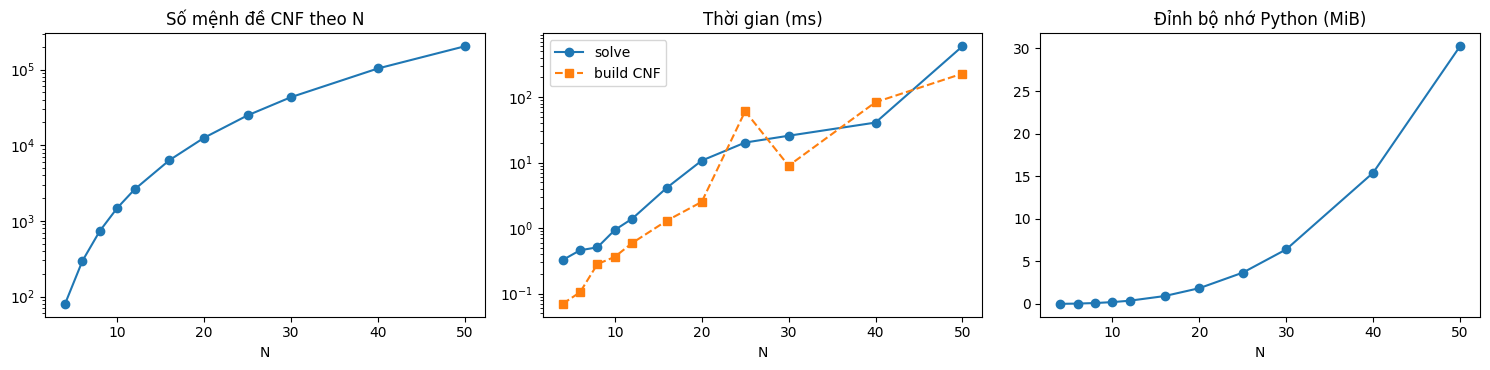

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(sat.n, sat.num_clauses, "o-"); ax[0].set_yscale("log"); ax[0].set_title("Số mệnh đề CNF theo N"); ax[0].set_xlabel("N")
ax[1].plot(sat.n, sat.solve_time_s * 1e3, "o-", label="solve"); ax[1].plot(sat.n, sat.build_time_s * 1e3, "s--", label="build CNF")
ax[1].set_yscale("log"); ax[1].set_title("Thời gian (ms)"); ax[1].set_xlabel("N"); ax[1].legend()
ax[2].plot(sat.n, sat.peak_mem_kb / 1024, "o-"); ax[2].set_title("Đỉnh bộ nhớ Python (MiB)"); ax[2].set_xlabel("N")
plt.tight_layout(); plt.show()

### 4.2 Min-Conflicts chuẩn vs Max-Conflict

In [9]:
view = summ.copy()
view["mean_time_ms"] = view.mean_time_s * 1e3
view[["method", "n", "runs", "success_rate", "mean_steps", "median_steps", "mean_time_ms", "mean_final_conflicts", "peak_mem_kb"]].round(3)

,method,n,runs,success_rate,mean_steps,median_steps,mean_time_ms,mean_final_conflicts,peak_mem_kb
0,MC_RANDOM,8,30,0.933,3367.567,24.0,15.347,0.067,4.328
1,MC_RANDOM,16,30,1.000,99.233,74.0,1.014,0.000,5.023
2,MC_RANDOM,32,30,1.000,95.533,96.0,1.748,0.000,7.992
3,MC_RANDOM,50,30,1.000,103.000,100.0,2.969,0.000,9.258
4,MC_RANDOM,100,30,1.000,140.267,128.0,7.066,0.000,20.523
5,MC_RANDOM,200,30,1.000,200.267,195.5,15.114,0.000,26.961
6,MC_MAX,8,30,0.767,11691.367,20.5,69.739,0.233,4.328
7,MC_MAX,16,30,0.967,1714.833,40.0,20.463,0.033,5.406
8,MC_MAX,32,30,1.000,46.367,41.0,1.536,0.000,8.508
9,MC_MAX,50,30,1.000,63.833,64.5,1.682,0.000,9.742


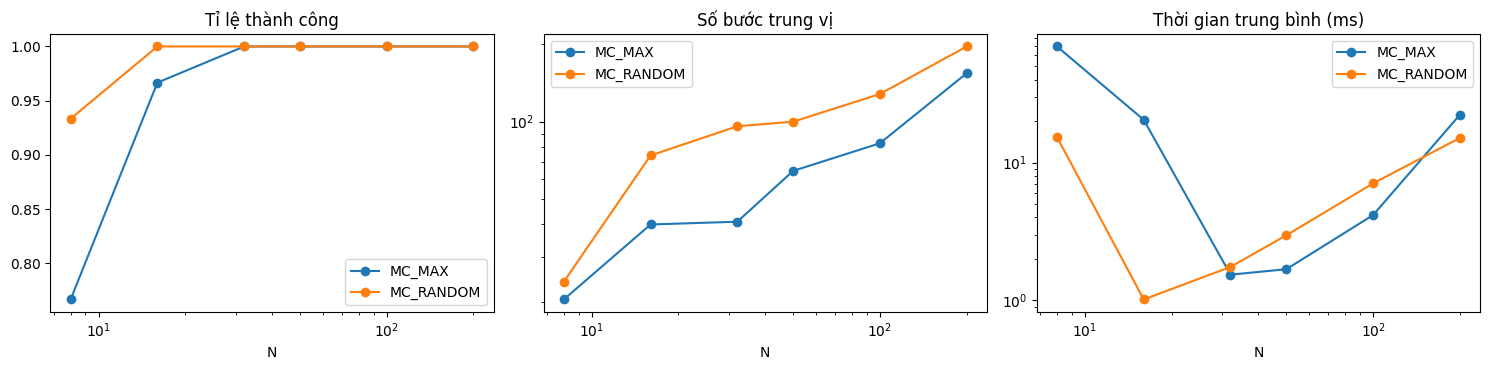

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for method, g in summ.groupby("method"):
    ax[0].plot(g.n, g.success_rate, "o-", label=method)
    ax[1].plot(g.n, g.median_steps, "o-", label=method)
    ax[2].plot(g.n, g.mean_time_s * 1e3, "o-", label=method)
ax[0].set_title("Tỉ lệ thành công"); ax[1].set_title("Số bước trung vị"); ax[2].set_title("Thời gian trung bình (ms)")
ax[1].set_yscale("log"); ax[2].set_yscale("log")
for a in ax: a.set_xscale("log"); a.set_xlabel("N"); a.legend()
plt.tight_layout(); plt.show()

Số bước trung bình bị kéo lên rất mạnh bởi các lần *kẹt* (chạm 50 000 bước) nên ngoài trung bình ta xem thêm **trung vị**, và so sánh **ghép cặp theo seed**
(cùng N, cùng seed ⇒ cùng bàn cờ khởi tạo) để biết heuristic thắng/thua bao nhiêu lần.

In [11]:
piv = runs.pivot_table(index=["n", "seed"], columns="method", values=["steps", "success"], aggfunc="first")
both_ok = piv["success"].all(axis=1)
cmp = piv["steps"][both_ok].copy()
res = (cmp.assign(max_fewer=cmp.MC_MAX < cmp.MC_RANDOM, rand_fewer=cmp.MC_MAX > cmp.MC_RANDOM)
          .groupby("n")[["max_fewer", "rand_fewer"]].mean())
res.columns = ["% cặp seed MC_MAX ít bước hơn", "% cặp seed MC_RANDOM ít bước hơn"]
(res * 100).round(1)

,% cặp seed MC_MAX ít bước hơn,% cặp seed MC_RANDOM ít bước hơn
n,,
8,59.1,31.8
16,69.0,31.0
32,86.7,13.3
50,80.0,16.7
100,76.7,20.0
200,83.3,16.7


In [12]:
fail = runs[~runs.success].groupby(["method", "n"]).size().rename("số lần thất bại (không giải được trong 50 000 bước)")
fail.to_frame()

số lần thất bại (không giải được trong 50 000 bước)
method    n                                                      
MC_MAX    8                                                   7  
          16                                                  1  
MC_RANDOM 8                                                   2

## 5. Nhận xét

*(Các nhận xét dưới đây dựa trên bảng và biểu đồ vừa sinh ra ở trên.)*

* **Encoding đúng**: số nghiệm đếm từ CNF khớp dãy 1, 0, 0, 2, 10, 4, 40, 92 và N=4 → 80, N=8 → 736 mệnh đề. Số mệnh đề tăng xấp xỉ **bậc 3** theo N vì với mỗi hàng/cột
  ta sinh $O(N^2)$ cặp; khi N = 50 đã khoảng 2×10⁵ mệnh đề.
* **Glucose3** luôn tìm được nghiệm với mọi N đã thử (4…50) và trả về UNSAT cho N=2,3. Thời gian giải vẫn tính bằng mili-giây đến dưới một giây; chi phí sinh CNF và bộ nhớ tăng nhanh hơn thời gian giải.
* **Min-Conflicts** chạy rất nhanh với N lớn (N=200 chỉ cần vài trăm bước) vì $O(1)$ cho mỗi truy vấn xung đột, trong khi SAT cần sinh $O(N^3)$ mệnh đề.
  Nhưng Min-Conflicts là thuật toán **không đầy đủ**: với N nhỏ (8, 16) có những lần kẹt ở cực tiểu cục bộ trong 50 000 bước (bảng thất bại ở trên); SAT thì luôn đủ/đúng.
* **Max-Conflict (heuristic)**: khi hai cách cùng giải được, Max-Conflict cần **ít bước hơn** ở mọi N đã thử (thắng khoảng 59–87% số cặp seed, rõ nhất ở N=32–200; xem bảng ghép cặp).
  Thời gian chạy ở N=200 vẫn gần như ngang nhau vì mỗi bước của Max-Conflict tốn hơn (phải xét mọi cột để tìm cột xung đột nhiều nhất).
  Đổi lại, ở N nhỏ (8, 16) nó **kém ổn định hơn**: có 7/30 lần thất bại ở N=8 và 1/30 ở N=16 (bản chuẩn: 2/30 ở N=8), vì chiến lược gần như xác định nên dễ mắc kẹt ở cực tiểu cục bộ.
  Danh sách tabu không loại bỏ hoàn toàn hiện tượng này (thử riêng với seed 100–199, độ dài tabu 0–8 đều còn thất bại ở N=8; thử nghiệm này không nằm trong notebook).
* **Hạn chế**: thời gian đo trên máy chạy notebook này (không phải macOS/Intel i5 của máy chấm); bộ nhớ chỉ là heap Python. Nên so sánh **tương đối** giữa các phương pháp thay vì giá trị tuyệt đối.